# Supplemental Info: Control Variable Adjustment Figures

## Control variable conventions

| Variable | Non-dimensional? | Total field? | Notes |
|---|---|---|---|
| `xx_*` (all vars) | **Yes** — O(0.01–3), normalized σ units | No — adjustment only | Both atmos and IC |
| `xx_*.effective` — 3D IC (θ, S, u, v) | No — physical units (°C, psu, m/s) | **Yes** — IC + adjustment + smoothing | Iter-0 effective = prior IC |
| `xx_*.effective` — 2D atmos | No — physical units (K, W/m², m/s, …) | **No** — adjustment + smoothing only | Iter-0 effective = 0 everywhere; background ERA forcing not stored in control files |

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from mitgcm_assim.ctrls import load_controls_and_sensitivities

In [3]:
# sep_data_dir = '/data/SO3/edavenport/tpose6/sep2012/run_ad_fixed_UVsigma' 
# nov_data_dir = '/data/SO3/edavenport/tpose6/nov2012/run_ad_fixed_UVsigma'
# jan_data_dir = '/data/SO3/edavenport/tpose6/jan2013/run_ad_fixed_UVsigma'
# mar_data_dir = '/data/SO3/edavenport/tpose6/mar2013/run_ad_fixed_UVsigma'

# sep_i0_dir = '/data/SO3/edavenport/tpose6/diags/sep2012/run_iter14/' 
# nov_i0_dir = '/data/SO3/edavenport/tpose6/nov2012/unconstrained_UV_IC/run_ad_withGLD'
# jan_i0_dir = '/data/SO3/edavenport/tpose6/jan2013/unconstrained_UV_IC/run_ad'
# mar_i0_dir = '/data/SO3/edavenport/tpose6/mar2013/unconstrained_UV_IC/run_ad'

sep_data_dir = '/data/SO3/edavenport/tpose6/diags/sep2012/run_iter14' 
nov_data_dir = '/data/SO3/edavenport/tpose6/diags/nov2012/run_iter20'
jan_data_dir = '/data/SO3/edavenport/tpose6/diags/jan2013/run_iter14'
mar_data_dir = '/data/SO3/edavenport/tpose6/diags/mar2013/run_iter16'

grid_dir = '/data/SO6/TPOSE_diags/tpose6/grid_6/'

sep_final_iter = 14
nov_final_iter = 20
jan_final_iter = 14
mar_final_iter = 16

folder_name = '/home/edavenport/analysis/vel-assim-manuscript/assimilation_controls/supplemental_xx/'

import os
os.makedirs(folder_name, exist_ok=True)

In [4]:
ds_sep = load_controls_and_sensitivities(sep_data_dir, grid_dir, sep_final_iter)
ds_nov = load_controls_and_sensitivities(nov_data_dir, grid_dir, nov_final_iter)
ds_jan = load_controls_and_sensitivities(jan_data_dir, grid_dir, jan_final_iter)
ds_mar = load_controls_and_sensitivities(mar_data_dir, grid_dir, mar_final_iter)

/home/edavenport/miniforge3/envs/tpose/lib/python3.12/site-packages/xmitgcm/mds_store.py:289: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds['time'] = xr.decode_cf(ds[['time']])['time']


/home/edavenport/miniforge3/envs/tpose/lib/python3.12/site-packages/xmitgcm/mds_store.py:289: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds['time'] = xr.decode_cf(ds[['time']])['time']


/home/edavenport/miniforge3/envs/tpose/lib/python3.12/site-packages/xmitgcm/mds_store.py:289: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds['time'] = xr.decode_cf(ds[['time']])['time']


/home/edavenport/miniforge3/envs/tpose/lib/python3.12/site-packages/xmitgcm/mds_store.py:289: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds['time'] = xr.decode_cf(ds[['time']])['time']


In [5]:
import xarray as xr

def filter_xx(ds):
    """Keep only xx* variables, renaming .effective → _effective to avoid
    xarray's dot-splitting virtual-variable behaviour (e.g. 'xx_precip.effective'
    would otherwise be parsed as accessing attribute 'effective' of 'xx_precip')."""
    new_vars = {}
    for v in list(ds.data_vars):
        sname = str(v)
        if sname.startswith('xx'):
            new_name = sname.replace('.effective', '_effective')
            # Access via internal _variables dict to skip __getitem__ dot-splitting
            new_vars[new_name] = ds._variables[sname]
    return xr.Dataset(new_vars, coords=ds.coords)

ds_sep = filter_xx(ds_sep)
ds_nov = filter_xx(ds_nov)
ds_jan = filter_xx(ds_jan)
ds_mar = filter_xx(ds_mar)

In [6]:
NX, NY, NZ = 1128, 336, 66
ERA5_DIR = '/data/globus/averdy/TPOSE_scratch/ERA5'

def load_era5_window_mean(fpath, start_hour, n_hours, nx=NX, ny=NY, chunk_hours=200):
    """Compute time-mean of an hourly ERA5 binary field over a window.
    Layout: big-endian float32, one (nx*ny) spatial record per hour,
    Fortran column-major spatial order (x/lon varies fastest)."""
    rec_size = nx * ny
    accumulator = np.zeros(rec_size, dtype=np.float64)
    hours_done = 0
    with open(fpath, 'rb') as f:
        f.seek(start_hour * rec_size * 4)
        while hours_done < n_hours:
            chunk = min(chunk_hours, n_hours - hours_done)
            raw = np.frombuffer(f.read(chunk * rec_size * 4), dtype='>f4').astype(np.float64)
            accumulator += raw.reshape(chunk, rec_size).sum(axis=0)
            hours_done += chunk
    return (accumulator / n_hours).reshape((nx, ny), order='F').T  # → (ny, nx)

def era5_mean_to_da(arr, ds_ref):
    """Wrap (ny, nx) numpy array as xr.DataArray with model grid coords."""
    return xr.DataArray(arr, dims=['YC', 'XC'],
                        coords={'YC': ds_ref.YC, 'XC': ds_ref.XC})

def load_bin_2d(fpath, nx=NX, ny=NY, ds_ref=None):
    """Load big-endian float32 2D binary → xr.DataArray (YC, XC)."""
    with open(fpath, 'rb') as f:
        raw = np.fromfile(f, dtype='>f4')
    arr = raw.reshape((nx, ny), order='F').T  # → (ny, nx)
    if ds_ref is not None:
        return xr.DataArray(arr, dims=['YC', 'XC'],
                            coords={'YC': ds_ref.YC, 'XC': ds_ref.XC})
    return arr

def load_bin_3d(fpath, nx=NX, ny=NY, nz=NZ, ds_ref=None):
    """Load big-endian float32 3D binary → xr.DataArray (Z, YC, XC)."""
    with open(fpath, 'rb') as f:
        raw = np.fromfile(f, dtype='>f4')
    arr = raw.reshape((nx, ny, nz), order='F').transpose(2, 1, 0)  # → (nz, ny, nx)
    if ds_ref is not None:
        return xr.DataArray(arr, dims=['Z', 'YC', 'XC'],
                            coords={'Z': ds_ref.Z, 'YC': ds_ref.YC, 'XC': ds_ref.XC})
    return arr

def sel_z_nearest(da, z_target):
    """Select nearest Z level without triggering big-endian pandas error."""
    z_idx = int(np.argmin(np.abs(da.Z.values.astype(float) - z_target)))
    return da.isel(Z=z_idx)


In [7]:
# ERA5 window hours (0-indexed from Jan 1 of the file year):
#   Sep 2012 (leap): days 0..243 before Sep 1 → start=5856h;  122d=2928h; file=2012
#   Nov 2012 (leap): days 0..304 before Nov 1 → start=7320h; crosses into 2013
#   Jan 2013:        start=0h;  122d=2928h; file=2013
#   Mar 2013:        days 0..58 before Mar 1 → start=1416h; file=2013
#
# EXF scaling applied to raw file values before model use:
#   swdown/lwdown: exf_inscal = -1.0  (stored as negative in ERA5 files)
#   atemp: exf_offset = 273.15 K  (file is in °C; offset cancels when we plot in °C)

era5_file_info = {
    # var_name:              (file_prefix,                    scale)
    'xx_atemp_effective':  ('ERA5_tmp2m_degC_troppac6',  1.0),
    'xx_aqh_effective':    ('ERA5_spfh2m_troppac6',       1.0),
    'xx_precip_effective': ('ERA5_rain_troppac6',          1.0),
    'xx_uwind_effective':  ('ERA5_u10m_troppac6',          1.0),
    'xx_vwind_effective':  ('ERA5_v10m_troppac6',          1.0),
    'xx_swdown_effective': ('ERA5_dsw_troppac6',          -1.0),  # inscal = -1
    'xx_lwdown_effective': ('ERA5_dlw_troppac6',          -1.0),  # inscal = -1
}

era5_means = {}  # {var: {season_label: 2D DataArray}}
ds_ref = ds_sep  # any dataset for YC/XC coords

for var, (prefix, scale) in era5_file_info.items():
    print(f'Loading ERA5 for {var}...')
    era5_means[var] = {}

    p2012 = f'{ERA5_DIR}/{prefix}_2012'
    p2013 = f'{ERA5_DIR}/{prefix}_2013'

    # Sep 2012: hour 5856, 2928 hours (Sep 1 – Dec 31 in 2012 leap-year file)
    era5_means[var]['Sep'] = era5_mean_to_da(
        load_era5_window_mean(p2012, 5856, 2928) * scale, ds_ref)

    # Nov 2012: straddles year boundary (61 days in 2012, 61 days in 2013)
    m2012 = load_era5_window_mean(p2012, 7320, 1464) * scale  # Nov 1 – Dec 31
    m2013 = load_era5_window_mean(p2013,    0, 1464) * scale  # Jan 1 – Mar 2
    era5_means[var]['Nov'] = era5_mean_to_da((m2012 + m2013) / 2, ds_ref)

    # Jan 2013: hour 0, 2928 hours
    era5_means[var]['Jan'] = era5_mean_to_da(
        load_era5_window_mean(p2013, 0, 2928) * scale, ds_ref)

    # Mar 2013: hour 1416, 2928 hours (Mar 1 – Jun 30)
    era5_means[var]['Mar'] = era5_mean_to_da(
        load_era5_window_mean(p2013, 1416, 2928) * scale, ds_ref)

print('ERA5 window means loaded.')

Loading ERA5 for xx_atemp_effective...
Loading ERA5 for xx_aqh_effective...
Loading ERA5 for xx_precip_effective...
Loading ERA5 for xx_uwind_effective...
Loading ERA5 for xx_vwind_effective...
Loading ERA5 for xx_swdown_effective...
Loading ERA5 for xx_lwdown_effective...
ERA5 window means loaded.


In [8]:
# Load control uncertainty weights (σ values)
# 2D atmos weights — use ds_sep for YC/XC coords
# 3D IC weights    — use ds_sep for Z, YC, XC coords

weights = {
    # IC (3D, shape nx×ny×nz in file → Z×YC×XC DataArray)
    'xx_theta': load_bin_3d('/data/SO6/TPOSE/model_setup/linked_files/TP6/Argo_T_wt_fac10_tp6_66.bin', ds_ref=ds_sep),
    'xx_salt':  load_bin_3d('/data/SO6/TPOSE/model_setup/linked_files/TP6/Argo_S_wt_fac10_tp6_66.bin', ds_ref=ds_sep),
    'xx_uvel':  load_bin_3d('/home/edavenport/analysis/TPOSE6_VelocityAssim/TAO_uvel_wt_tp6.bin',       ds_ref=ds_sep),
    'xx_vvel':  load_bin_3d('/home/edavenport/analysis/TPOSE6_VelocityAssim/TAO_vvel_wt_tp6.bin',       ds_ref=ds_sep),
    # Atmos (2D, shape nx×ny in file → YC×XC DataArray)
    'xx_atemp':  load_bin_2d('/data/SO6/TPOSE/model_setup/linked_files/TP6/ERA_tmp2m_degC_wt_tp6.bin', ds_ref=ds_sep),
    'xx_aqh':    load_bin_2d('/data/SO6/TPOSE/model_setup/linked_files/TP6/ERA_spfh2m_wt_tp6.bin',     ds_ref=ds_sep),
    'xx_precip': load_bin_2d('/data/SO6/TPOSE/model_setup/linked_files/TP6/ERA_rain_wt_tp6.bin',       ds_ref=ds_sep),
    'xx_uwind':  load_bin_2d('/data/SO6/TPOSE/model_setup/linked_files/TP6/ERA_u10m_wt_tp6.bin',       ds_ref=ds_sep),
    'xx_vwind':  load_bin_2d('/data/SO6/TPOSE/model_setup/linked_files/TP6/ERA_v10m_wt_tp6.bin',       ds_ref=ds_sep),
    'xx_swdown': load_bin_2d('/data/SO6/TPOSE/model_setup/linked_files/TP6/ERA_dsw_wt_tp6.bin',        ds_ref=ds_sep),
    'xx_lwdown': load_bin_2d('/data/SO6/TPOSE/model_setup/linked_files/TP6/ERA_dlw_wt_tp6.bin',        ds_ref=ds_sep),
}
print('Weights loaded.')

Weights loaded.


In [9]:
path = 'tao_moorings.txt'

# List comprehension to filter out comments/empty lines and convert to float tuples
tao_moorings = [tuple(map(float, l.split())) for l in open(path) if not l.strip().startswith('#') and l.strip()]

highlight = {(220, 0), (190, 0), (250, 0)}

In [10]:
def make_control_figure(datasets, variables, reduce_fn, colorbar_label,
                        figsize=(17, 9), savepath=None, pct_low=2, vlims_override=None):
    """
    Parameters
    ----------
    colorbar_label : str or dict {var_name: str}
    pct_low : float  — lower percentile for sequential colorbars (default 2)
    vlims_override : dict {var_name: (vmin, vmax)}  — None entries use computed value
    """
    proj = ccrs.PlateCarree(central_longitude=180)
    n_rows = len(variables)
    n_cols = len(datasets)

    reduced = {
        var: {lbl: reduce_fn(ds[var]) for lbl, ds in datasets.items()}
        for var in variables
    }

    vlims = {}
    for var, (title, cmap, signed) in variables.items():
        maps = list(reduced[var].values())
        finite_vals = np.concatenate([m.values[np.isfinite(m.values)].ravel() for m in maps])
        nonzero = finite_vals[finite_vals != 0]
        flat = nonzero if len(nonzero) > 0 else finite_vals
        if signed:
            vmax = float(np.percentile(np.abs(flat), 99))
            vlims[var] = (-vmax, vmax)
        else:
            vlims[var] = (float(np.percentile(flat, pct_low)),
                          float(np.percentile(flat, 98)))

    if vlims_override:
        for var, (ov_min, ov_max) in vlims_override.items():
            if var in vlims:
                cur_min, cur_max = vlims[var]
                vlims[var] = (ov_min if ov_min is not None else cur_min,
                              ov_max if ov_max is not None else cur_max)

    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(
        n_rows, n_cols + 1,
        width_ratios=[1] * n_cols + [0.03],
        wspace=0.15, hspace=0.12
    )

    for row, (var, (title, cmap, signed)) in enumerate(variables.items()):
        vmin, vmax_val = vlims[var]
        cax = fig.add_subplot(gs[row, n_cols])
        im = None

        for col, (lbl, rmap) in enumerate(reduced[var].items()):
            ax = fig.add_subplot(gs[row, col], projection=proj)
            ax.set_aspect("auto")
            ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor="black")
            ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=1)
            xmin = float(rmap.XC.min())
            xmax = float(rmap.XC.max())
            ax.set_extent([xmin, xmax, -17, 17], crs=ccrs.PlateCarree())
            im = rmap.plot(ax=ax, add_colorbar=False, cmap=cmap,
                           vmin=vmin, vmax=vmax_val,
                           transform=ccrs.PlateCarree(), x="XC", y="YC")
            for (lon, lat) in tao_moorings:
                color = "red" if (lon, lat) in highlight else "white"
                ax.plot(lon, lat, marker="o", color=color, markersize=4,
                        markeredgecolor="black", markeredgewidth=0.5,
                        transform=ccrs.PlateCarree(), zorder=5)
            gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray",
                              alpha=0.5, linestyle="--", crs=ccrs.PlateCarree())
            gl.left_labels   = (col == 0)
            gl.right_labels  = False
            gl.top_labels    = False
            gl.bottom_labels = (row == n_rows - 1)
            gl.xlabel_style  = {"size": 12}
            gl.ylabel_style  = {"size": 12}
            ax.set_title(lbl if row == 0 else "", fontsize=14, fontweight="bold")
            if col == 0:
                ax.text(0.02, 0.97, title, transform=ax.transAxes,
                        fontsize=12, fontweight="bold", va="top", ha="left",
                        bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                                  alpha=1.0, edgecolor="gray", linewidth=0.5))

        cb_label = colorbar_label[var] if isinstance(colorbar_label, dict) else colorbar_label
        fig.colorbar(im, cax=cax, label=cb_label)

    if savepath:
        plt.savefig(savepath, bbox_inches="tight")
    plt.show()

In [11]:
import xarray as xr

datasets = {'Sep': ds_sep, 'Nov': ds_nov, 'Jan': ds_jan, 'Mar': ds_mar}

def make_total_datasets(datasets_in, era5_means):
    """Add ERA5 window-mean to atmospheric xx_*_effective variables.
    IC effective vars are already full-field totals — left unchanged."""
    result = {}
    for lbl, ds in datasets_in.items():
        new_vars = {}
        for var in ds.data_vars:
            vname = str(var)
            if vname in era5_means and lbl in era5_means[vname]:
                new_vars[vname] = ds[vname] + era5_means[vname][lbl]
            else:
                new_vars[vname] = ds[vname]
        result[lbl] = xr.Dataset(new_vars, coords=ds.coords)
    return result

def make_phys_adj_datasets(datasets_in, weights):
    """Convert non-dimensional xx_* adjustments to physical units; weights contain 1/σ²."""
    result = {}
    for lbl, ds in datasets_in.items():
        new_vars = {}
        for var in ds.data_vars:
            vname = str(var)
            if vname in weights:
                w = weights[vname]
                new_vars[vname] = ds[vname] / np.sqrt(w.where(w > 0))
            else:
                new_vars[vname] = ds[vname]
        result[lbl] = xr.Dataset(new_vars, coords=ds.coords)
    return result

datasets_total    = make_total_datasets(datasets, era5_means)
datasets_adj_phys = make_phys_adj_datasets(datasets, weights)
print('xx datasets constructed.')

xx datasets constructed.


## Mean Control Adjustments (`xx` at final iteration)

The control adjustment is the normalized correction added by the assimilation
(in units of the prior standard deviation $\sigma$).  For atmospheric controls,
each panel shows the time-mean adjustment.  For initial-condition controls,
each panel shows the depth-mean adjustment.

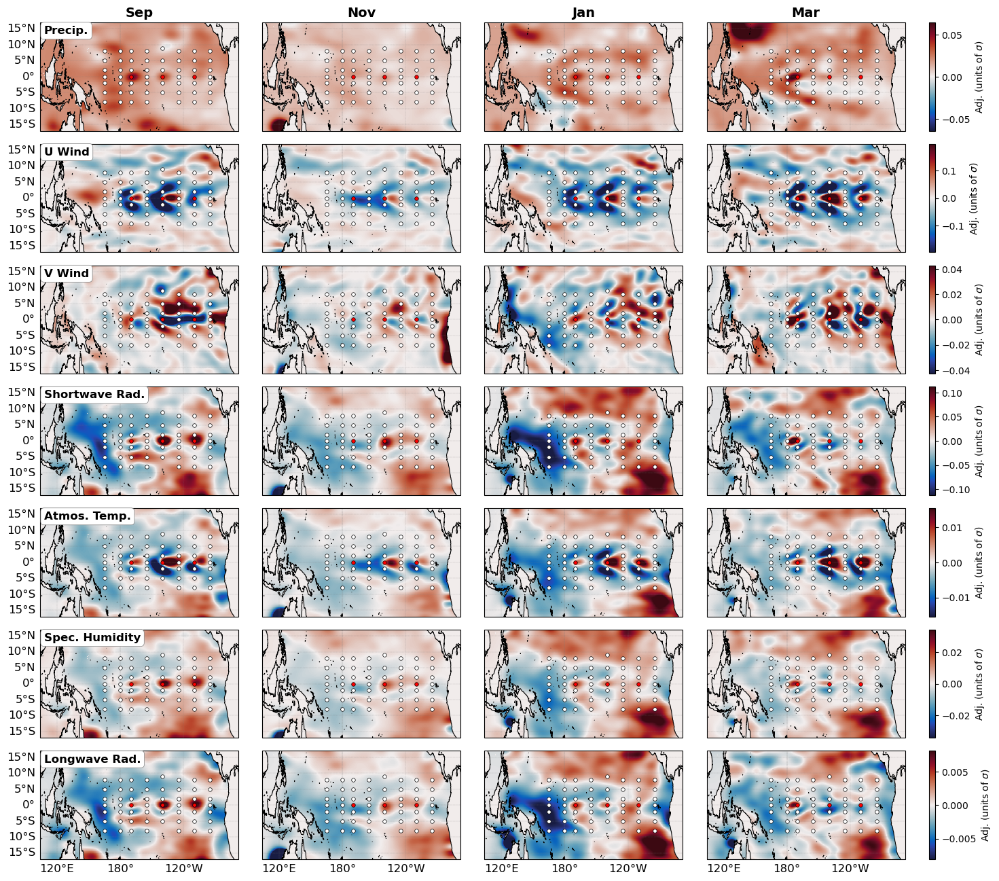

In [12]:
# Mean adjustment — atmospheric controls
variables = {
    'xx_precip': ('Precip.',        cmocean.cm.balance, True),
    'xx_uwind':  ('U Wind',         cmocean.cm.balance, True),
    'xx_vwind':  ('V Wind',         cmocean.cm.balance, True),
    'xx_swdown': ('Shortwave Rad.', cmocean.cm.balance, True),
    'xx_atemp':  ('Atmos. Temp.',   cmocean.cm.balance, True),
    'xx_aqh':    ('Spec. Humidity', cmocean.cm.balance, True),
    'xx_lwdown': ('Longwave Rad.',  cmocean.cm.balance, True),
}

make_control_figure(
    datasets, variables,
    reduce_fn=lambda da: da.mean(dim='time'),
    colorbar_label='Adj. (units of $\\sigma$)',
    figsize=(17, 16),
    savepath=folder_name + 'mean_adj_atmos.png'
)

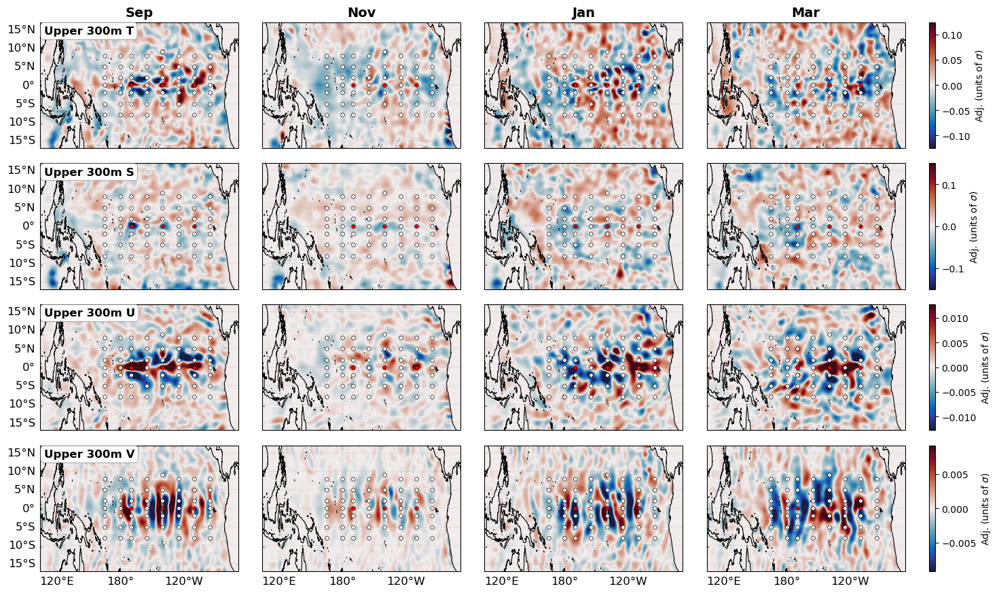

In [13]:
# Mean adjustment — IC controls, upper 300 m mean
variables = {
    'xx_theta': ('Upper 300m T', cmocean.cm.balance, True),
    'xx_salt':  ('Upper 300m S', cmocean.cm.balance, True),
    'xx_uvel':  ('Upper 300m U', cmocean.cm.balance, True),
    'xx_vvel':  ('Upper 300m V', cmocean.cm.balance, True),
}

make_control_figure(
    datasets, variables,
    reduce_fn=lambda da: da.where(da.Z >= -300, drop=True).mean(dim='Z'),
    colorbar_label='Adj. (units of $\\sigma$)',
    figsize=(17, 10.5),
    savepath=folder_name + 'mean_adj_ic_upper300m.png'
)

## Control Adjustments in Physical Units (`xx * σ` at final iteration)

Same as the previous section but with each non-dimensional adjustment multiplied by its
prior uncertainty weight σ, converting to physical units (°C, psu, m/s, W/m², kg/kg, m/s).

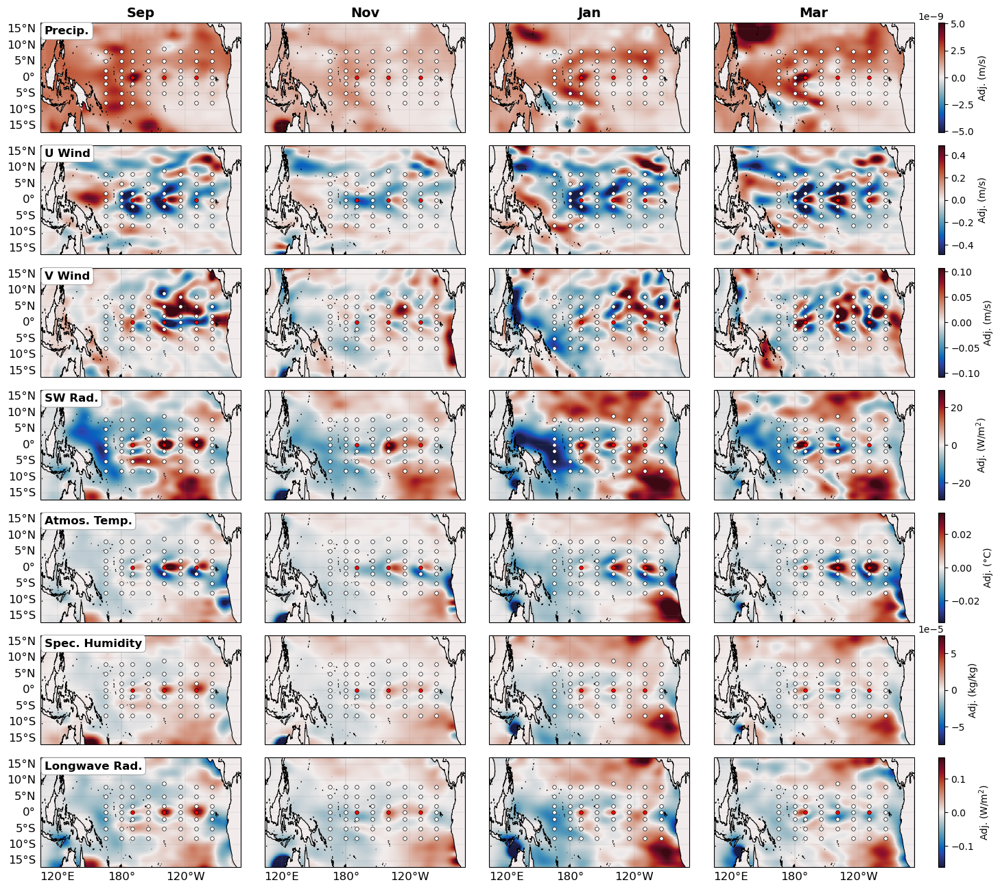

In [14]:
# Mean adjustment in physical units — atmospheric controls
variables = {
    'xx_precip': ('Precip.',        cmocean.cm.balance, True),
    'xx_uwind':  ('U Wind',         cmocean.cm.balance, True),
    'xx_vwind':  ('V Wind',         cmocean.cm.balance, True),
    'xx_swdown': ('SW Rad.',        cmocean.cm.balance, True),
    'xx_atemp':  ('Atmos. Temp.',   cmocean.cm.balance, True),
    'xx_aqh':    ('Spec. Humidity', cmocean.cm.balance, True),
    'xx_lwdown': ('Longwave Rad.',  cmocean.cm.balance, True),
}
colorbar_label = {
    'xx_precip': 'Adj. (m/s)',
    'xx_uwind':  'Adj. (m/s)',
    'xx_vwind':  'Adj. (m/s)',
    'xx_swdown': r'Adj. (W/m$^2$)',
    'xx_atemp':  'Adj. (°C)',
    'xx_aqh':    'Adj. (kg/kg)',
    'xx_lwdown': r'Adj. (W/m$^2$)',
}

make_control_figure(
    datasets_adj_phys, variables,
    reduce_fn=lambda da: da.mean(dim='time'),
    colorbar_label=colorbar_label,
    figsize=(17, 16),
    savepath=folder_name + 'mean_adj_atmos_physical.png'
)

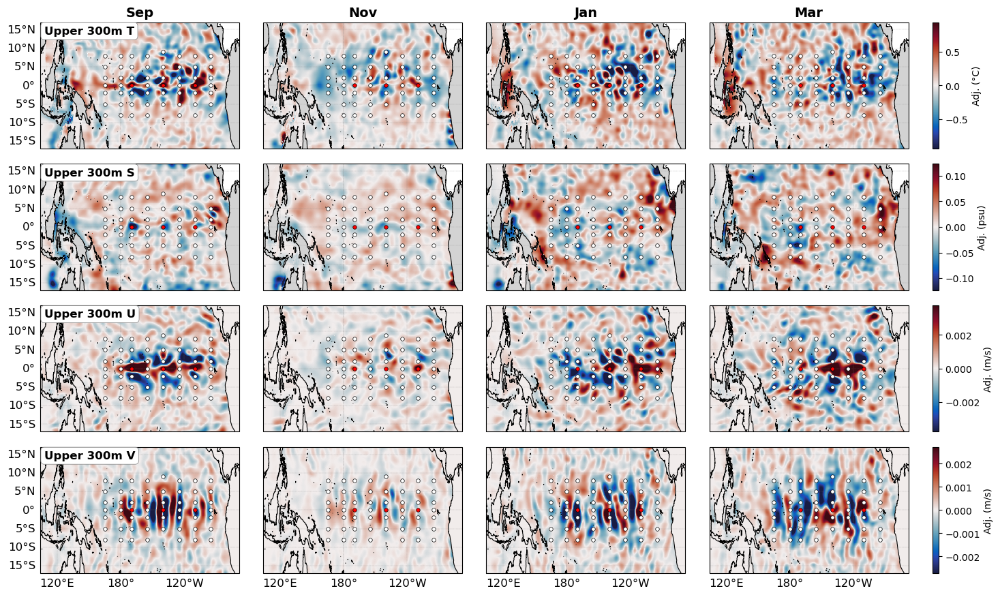

In [15]:
# Mean adjustment in physical units — IC controls, upper 300 m mean
variables = {
    'xx_theta': ('Upper 300m T', cmocean.cm.balance, True),
    'xx_salt':  ('Upper 300m S', cmocean.cm.balance, True),
    'xx_uvel':  ('Upper 300m U', cmocean.cm.balance, True),
    'xx_vvel':  ('Upper 300m V', cmocean.cm.balance, True),
}
colorbar_label = {
    'xx_theta': 'Adj. (°C)',
    'xx_salt':  'Adj. (psu)',
    'xx_uvel':  'Adj. (m/s)',
    'xx_vvel':  'Adj. (m/s)',
}

make_control_figure(
    datasets_adj_phys, variables,
    reduce_fn=lambda da: da.where(da.Z >= -300, drop=True).mean(dim='Z'),
    colorbar_label=colorbar_label,
    figsize=(17, 10.5),
    savepath=folder_name + 'mean_adj_ic_upper300m_physical.png'
)

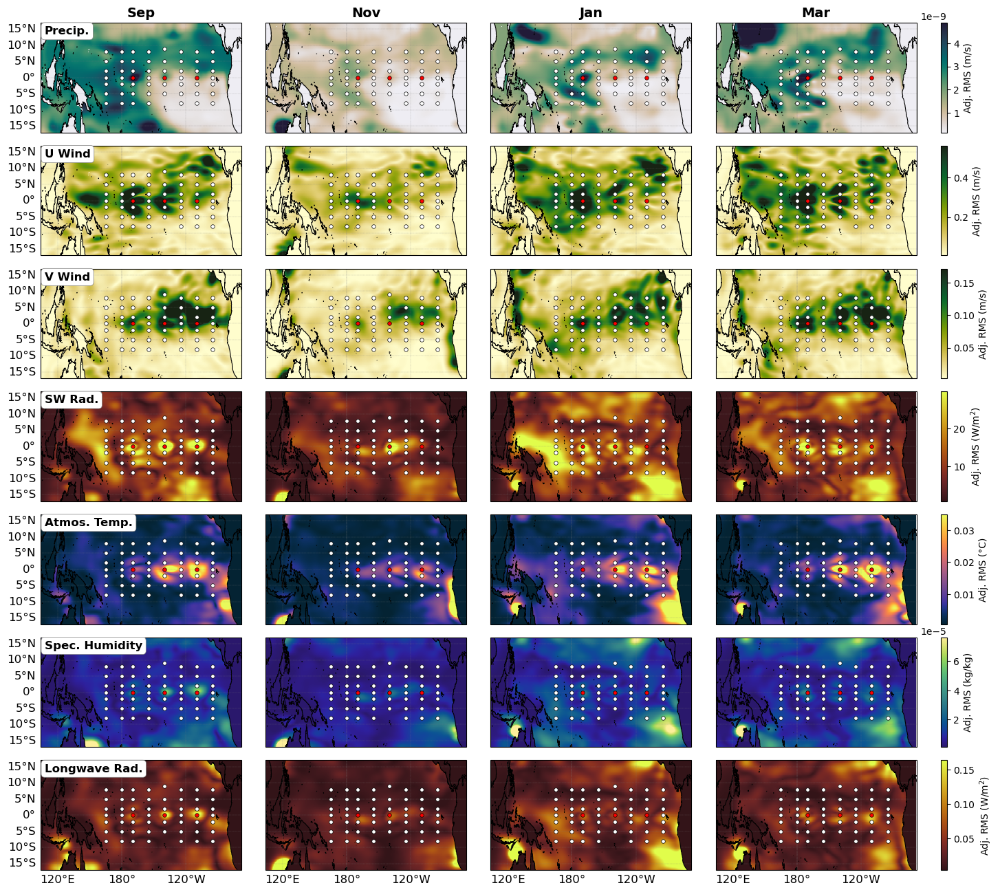

In [16]:
# RMS adjustment in physical units — atmospheric controls (RMS over time)
variables = {
    'xx_precip': ('Precip.',        cmocean.cm.rain,    False),
    'xx_uwind':  ('U Wind',         cmocean.cm.speed,   False),
    'xx_vwind':  ('V Wind',         cmocean.cm.speed,   False),
    'xx_swdown': ('SW Rad.',        cmocean.cm.solar,   False),
    'xx_atemp':  ('Atmos. Temp.',   cmocean.cm.thermal, False),
    'xx_aqh':    ('Spec. Humidity', cmocean.cm.haline,  False),
    'xx_lwdown': ('Longwave Rad.',  cmocean.cm.solar,   False),
}
colorbar_label = {
    'xx_precip': 'Adj. RMS (m/s)',
    'xx_uwind':  'Adj. RMS (m/s)',
    'xx_vwind':  'Adj. RMS (m/s)',
    'xx_swdown': r'Adj. RMS (W/m$^2$)',
    'xx_atemp':  'Adj. RMS (°C)',
    'xx_aqh':    'Adj. RMS (kg/kg)',
    'xx_lwdown': r'Adj. RMS (W/m$^2$)',
}

make_control_figure(
    datasets_adj_phys, variables,
    reduce_fn=lambda da: np.sqrt((da**2).mean(dim='time')),
    colorbar_label=colorbar_label,
    figsize=(17, 16),
    savepath=folder_name + 'rms_adj_atmos_physical.png'
)

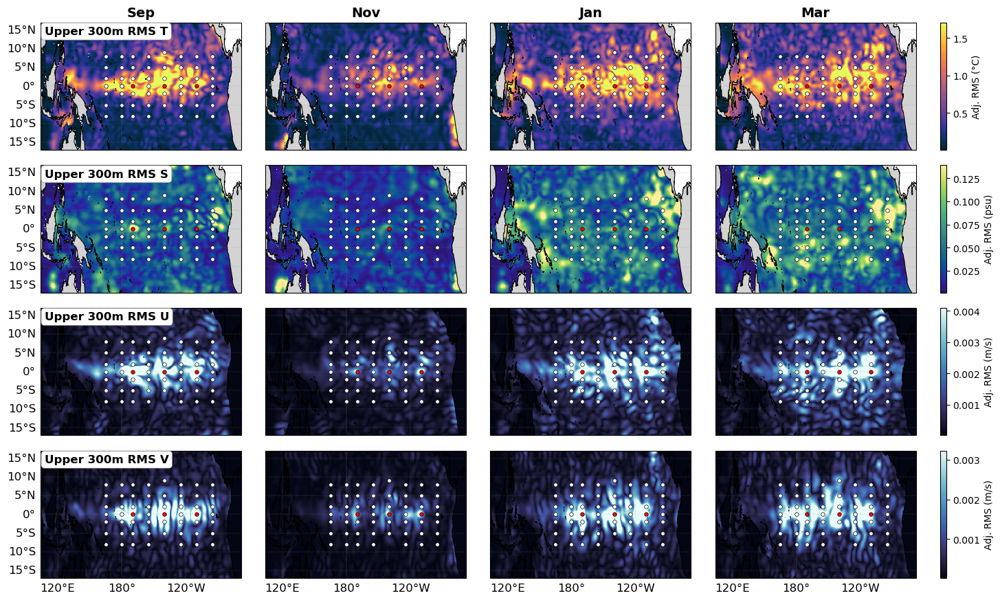

In [17]:
# RMS adjustment in physical units — IC controls, upper 300 m
variables = {
    'xx_theta': ('Upper 300m RMS T', cmocean.cm.thermal, False),
    'xx_salt':  ('Upper 300m RMS S', cmocean.cm.haline,  False),
    'xx_uvel':  ('Upper 300m RMS U', cmocean.cm.ice,     False),
    'xx_vvel':  ('Upper 300m RMS V', cmocean.cm.ice,     False),
}
colorbar_label = {
    'xx_theta': 'Adj. RMS (°C)',
    'xx_salt':  'Adj. RMS (psu)',
    'xx_uvel':  'Adj. RMS (m/s)',
    'xx_vvel':  'Adj. RMS (m/s)',
}

make_control_figure(
    datasets_adj_phys, variables,
    reduce_fn=lambda da: np.sqrt((da**2).where(da.Z >= -300, drop=True).mean(dim='Z')),
    colorbar_label=colorbar_label,
    figsize=(17, 10.5),
    savepath=folder_name + 'rms_adj_ic_upper300m_physical.png'
)

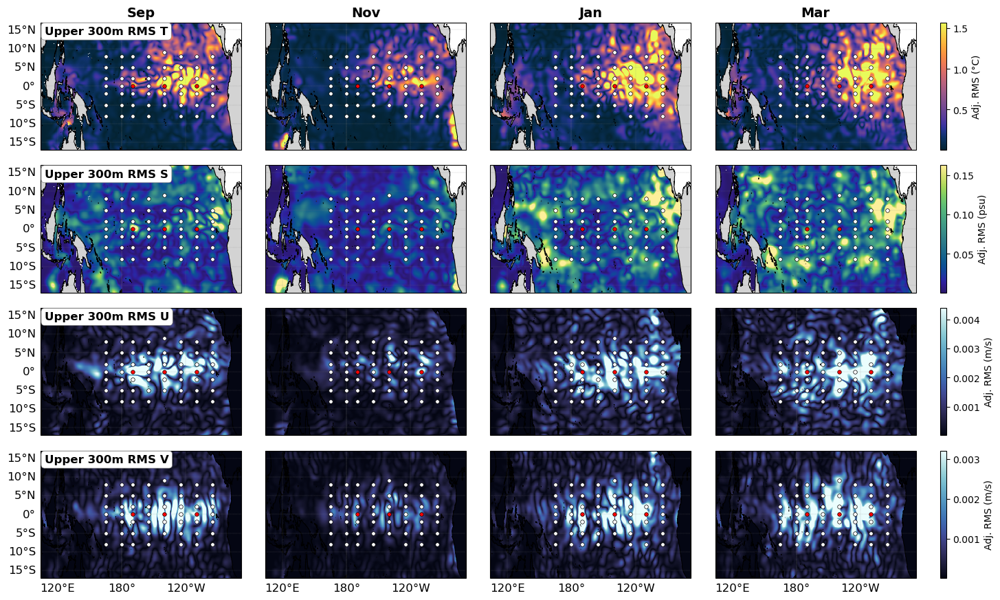

In [23]:
# RMS adjustment in physical units — IC controls, upper 300 m
variables = {
    'xx_theta': ('Upper 300m RMS T', cmocean.cm.thermal, False),
    'xx_salt':  ('Upper 300m RMS S', cmocean.cm.haline,  False),
    'xx_uvel':  ('Upper 300m RMS U', cmocean.cm.ice,     False),
    'xx_vvel':  ('Upper 300m RMS V', cmocean.cm.ice,     False),
}
colorbar_label = {
    'xx_theta': 'Adj. RMS (°C)',
    'xx_salt':  'Adj. RMS (psu)',
    'xx_uvel':  'Adj. RMS (m/s)',
    'xx_vvel':  'Adj. RMS (m/s)',
}

make_control_figure(
    datasets_adj_phys, variables,
    reduce_fn=lambda da: np.sqrt((da**2).where(da.Z >= -100, drop=True).mean(dim='Z')),
    colorbar_label=colorbar_label,
    figsize=(17, 10.5),
    savepath=folder_name + 'rms_adj_ic_upper100m_physical.png'
)

## Mean Total Controls (`xx*.effective` at final iteration)

The total control is the sum of the background and all assimilation adjustments
(i.e., what is actually applied to the model).  Each panel shows the time-mean
(atmospheric) or depth-mean (initial condition) of the effective control at the
final iteration.

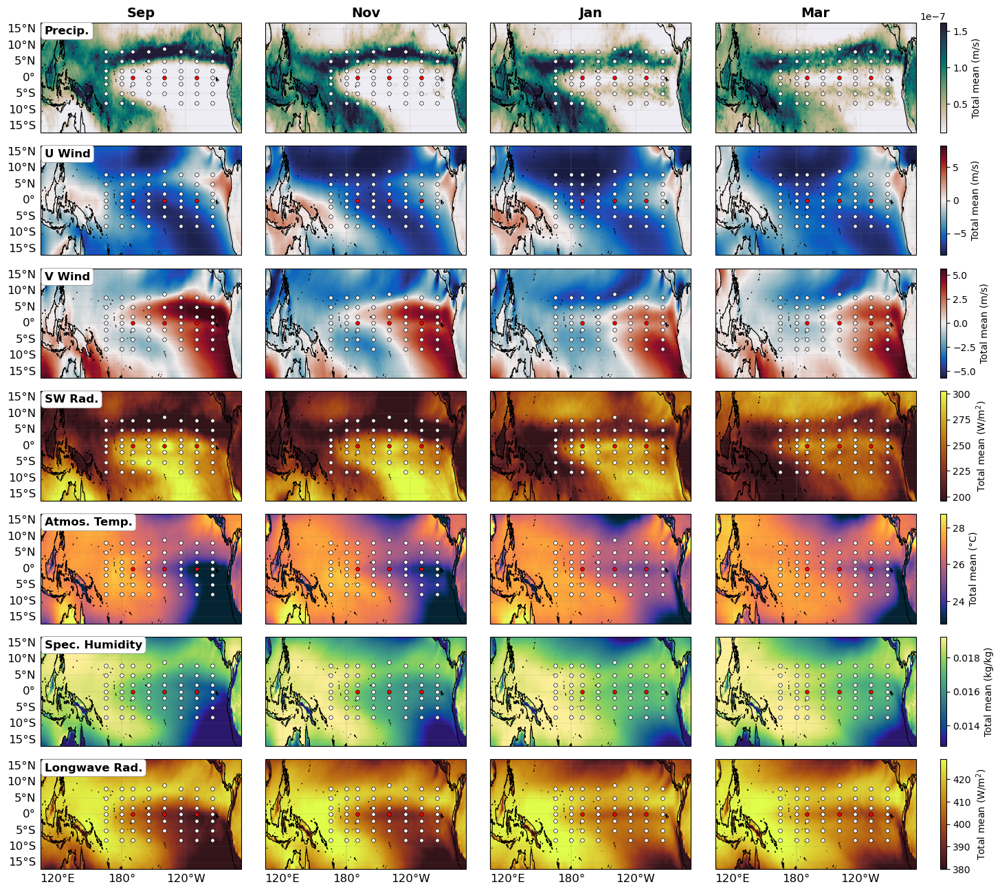

In [18]:
# Mean total control — atmospheric (ERA5 prior + adjustment, time mean)
variables = {
    'xx_precip_effective': ('Precip.',        cmocean.cm.rain,    False),
    'xx_uwind_effective':  ('U Wind',         cmocean.cm.balance, True),
    'xx_vwind_effective':  ('V Wind',         cmocean.cm.balance, True),
    'xx_swdown_effective': ('SW Rad.',        cmocean.cm.solar,   False),
    'xx_atemp_effective':  ('Atmos. Temp.',   cmocean.cm.thermal, False),
    'xx_aqh_effective':    ('Spec. Humidity', cmocean.cm.haline,  False),
    'xx_lwdown_effective': ('Longwave Rad.',  cmocean.cm.solar,   False),
}
colorbar_label = {
    'xx_precip_effective': 'Total mean (m/s)',
    'xx_uwind_effective':  'Total mean (m/s)',
    'xx_vwind_effective':  'Total mean (m/s)',
    'xx_swdown_effective': r'Total mean (W/m$^2$)',
    'xx_atemp_effective':  'Total mean (°C)',
    'xx_aqh_effective':    'Total mean (kg/kg)',
    'xx_lwdown_effective': r'Total mean (W/m$^2$)',
}
make_control_figure(
    datasets_total, variables,
    reduce_fn=lambda da: da.mean(dim='time'),
    colorbar_label=colorbar_label,
    figsize=(17, 16),
    pct_low=20,
    savepath=folder_name + 'mean_effective_atmos.png'
)

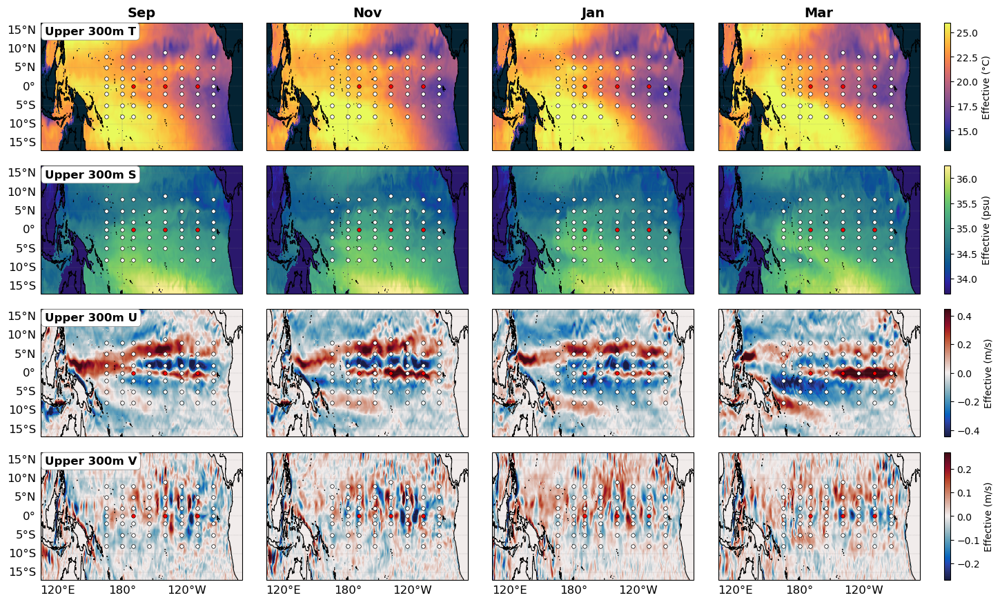

In [19]:
# Effective IC controls — upper 300 m mean (xx_*_effective at final iteration)
variables = {
    'xx_theta_effective': ('Upper 300m T', cmocean.cm.thermal, False),
    'xx_salt_effective':  ('Upper 300m S', cmocean.cm.haline,  False),
    'xx_uvel_effective':  ('Upper 300m U', cmocean.cm.balance, True),
    'xx_vvel_effective':  ('Upper 300m V', cmocean.cm.balance, True),
}
colorbar_label = {
    'xx_theta_effective': 'Effective (°C)',
    'xx_salt_effective':  'Effective (psu)',
    'xx_uvel_effective':  'Effective (m/s)',
    'xx_vvel_effective':  'Effective (m/s)',
}
make_control_figure(
    datasets, variables,
    reduce_fn=lambda da: da.where(da.Z >= -300, drop=True).mean(dim='Z'),
    colorbar_label=colorbar_label,
    figsize=(17, 10.5),
    vlims_override={'xx_salt_effective': (33.7, 36.25),'xx_theta_effective': (13, 26)}, 
    savepath=folder_name + 'effective_ic_upper300m.png'
)

## RMS of Total Controls (`xx*.effective` at final iteration)

Root-mean-square of the effective (total) control, reducing over the time dimension
for atmospheric variables and the depth dimension for initial-condition variables.
This is the analogue of the RMS adjustment figures in `tpose_vel_controls.ipynb`,
but applied to the full effective control rather than the normalized adjustment.

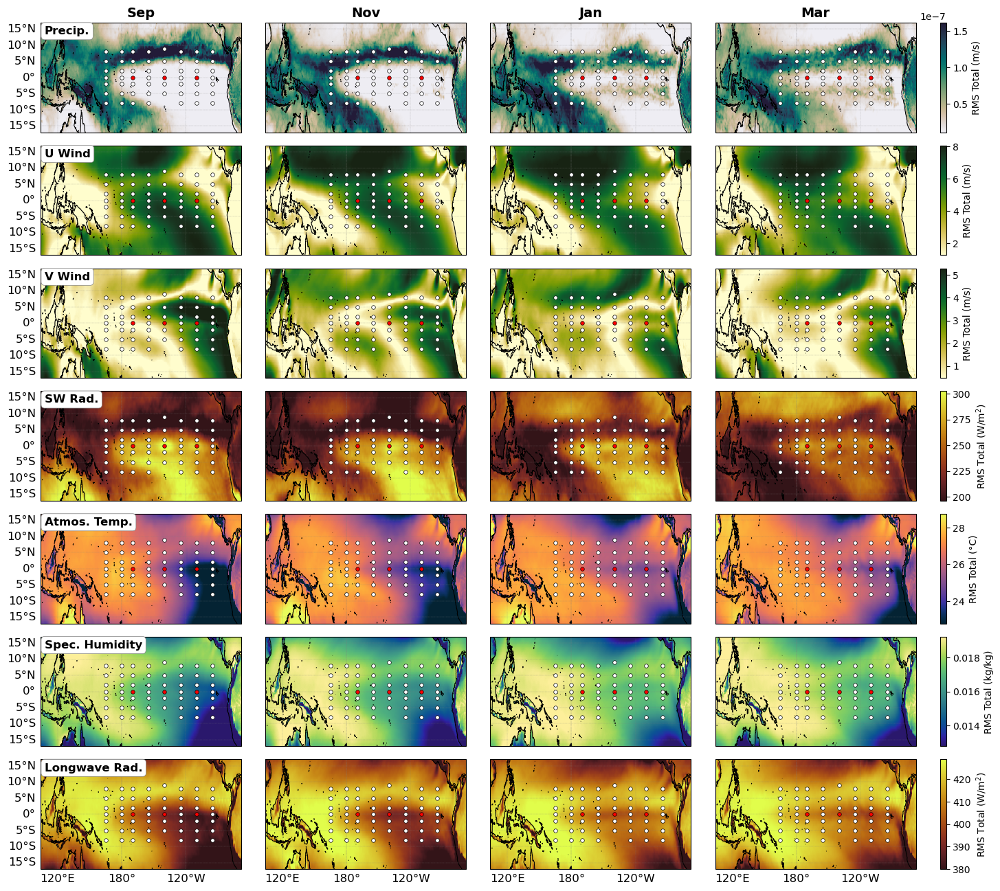

In [20]:
# RMS total control — atmospheric (ERA5 prior + adjustment, RMS over time)
variables = {
    'xx_precip_effective': ('Precip.',        cmocean.cm.rain,    False),
    'xx_uwind_effective':  ('U Wind',         cmocean.cm.speed,   False),
    'xx_vwind_effective':  ('V Wind',         cmocean.cm.speed,   False),
    'xx_swdown_effective': ('SW Rad.',        cmocean.cm.solar,   False),
    'xx_atemp_effective':  ('Atmos. Temp.',   cmocean.cm.thermal, False),
    'xx_aqh_effective':    ('Spec. Humidity', cmocean.cm.haline,  False),
    'xx_lwdown_effective': ('Longwave Rad.',  cmocean.cm.solar,   False),
}
colorbar_label = {
    'xx_precip_effective': 'RMS Total (m/s)',
    'xx_uwind_effective':  'RMS Total (m/s)',
    'xx_vwind_effective':  'RMS Total (m/s)',
    'xx_swdown_effective': r'RMS Total (W/m$^2$)',
    'xx_atemp_effective':  'RMS Total (°C)',
    'xx_aqh_effective':    'RMS Total (kg/kg)',
    'xx_lwdown_effective': r'RMS Total (W/m$^2$)',
}
make_control_figure(
    datasets_total, variables,
    reduce_fn=lambda da: np.sqrt((da**2).mean(dim='time')),
    colorbar_label=colorbar_label,
    figsize=(17, 16),
    pct_low=20,
    savepath=folder_name + 'rms_effective_atmos.png'
)

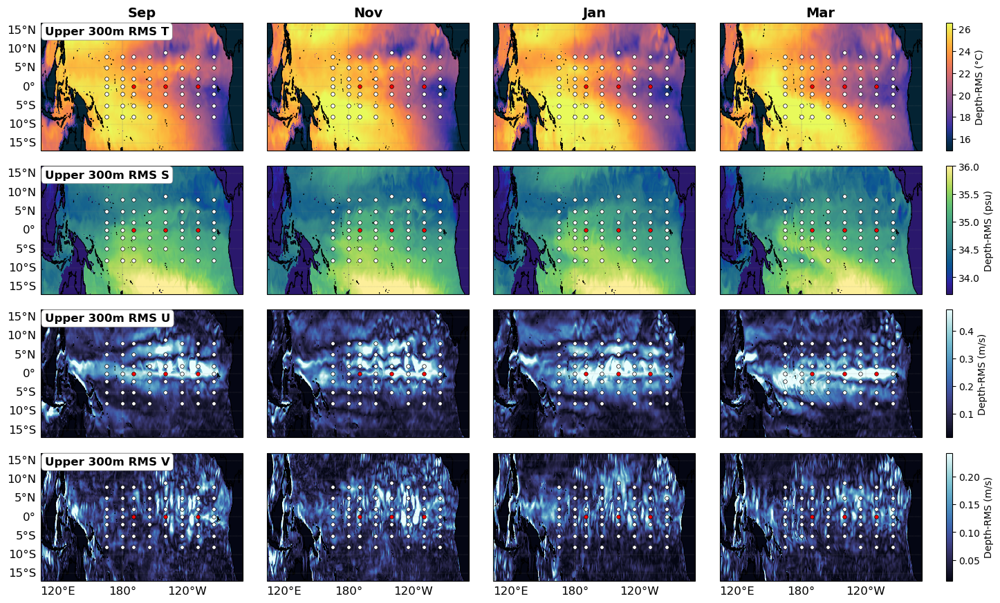

In [21]:
# RMS effective IC controls — upper 300 m (xx_*_effective at final iteration)
variables = {
    'xx_theta_effective': ('Upper 300m RMS T', cmocean.cm.thermal, False),
    'xx_salt_effective':  ('Upper 300m RMS S', cmocean.cm.haline,  False),
    'xx_uvel_effective':  ('Upper 300m RMS U', cmocean.cm.ice,     False),
    'xx_vvel_effective':  ('Upper 300m RMS V', cmocean.cm.ice,     False),
}
colorbar_label = {
    'xx_theta_effective': 'Depth-RMS (°C)',
    'xx_salt_effective':  'Depth-RMS (psu)',
    'xx_uvel_effective':  'Depth-RMS (m/s)',
    'xx_vvel_effective':  'Depth-RMS (m/s)',
}
make_control_figure(
    datasets, variables,
    reduce_fn=lambda da: np.sqrt((da**2).where(da.Z >= -300, drop=True).mean(dim='Z')),
    colorbar_label=colorbar_label,
    figsize=(17, 10.5),
    vlims_override={'xx_salt_effective': (33.7, 36.0)}, 
    savepath=folder_name + 'rms_effective_ic_upper300m.png'
)